In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import pandas as pd

import sys
import os
import time

# Add the parent directory to sys.path
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)

import matplotlib.gridspec as gridspec

#plt.style.use('ggplot')
# plt.style.use('seaborn-v0_8-ticks')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])


method_markers = {
    "GKS": "o",
    "S-GKS": "o",
    "resS-GKS": "v",
    "recS-GKS": "^",
    "PS-GKS": "o",
    "resPS-GKS": "v",
    "recPS-GKS": "^",
    "PS-GKB": "o",
    "FGK": "o",
    "FLSQR-I": "$\\text{I}$",
    "FLSQR-R": "$\\text{R}$",
    "FLSQR-W": "$*$",
    "IRW-FLSQR": "x",
}

method_colors = {
    "GKS": "C1",
    "S-GKS": "C4",
    "resS-GKS": "C4",
    "recS-GKS": "C4",
    "PS-GKS": "C2",
    "resPS-GKS": "C2",
    "recPS-GKS": "C2",
    "PS-GKB": "C5",
    "FGK": "C3",
    "FLSQR-I": "C3",
    "FLSQR-R": "C3",
    "FLSQR-W": "C3",
    "IRW-FLSQR": "C3",
}

method_lines = {
    "GKS": "solid",
    "S-GKS": "solid",
    "resS-GKS": "dotted",
    "recS-GKS": "dashed",
    "PS-GKS": "solid",
    "resPS-GKS": "dotted",
    "recPS-GKS": "dashed",
    "PS-GKB": "solid",
    "FGK": "solid",
    "FLSQR-I": "solid",
    "FLSQR-R": "solid",
    "FLSQR-W": "solid",
    "IRW-FLSQR": "solid",
}


from trips.utilities.weights import smoothed_holder_weights


# from fsolver import IASFGK, MMFGK, MM2019FGK # VanillaFK
# from pgkbsolver import MMGKB, IASGKB, MM2019GKB
# from f2019solver import MM2019FGK2019, IASFGK2019


from msolver import VanillaGKS

# For reference, to match papers exactly:
# SGKS corresponds to msolver, MM2GKS ?
# SGKS (restarted) corresponds to msolver, MM1GKS
# SGKS (recycled) corresponds to msolver, MM2GKS ?
# PSGKS corresponds to msolver, MM2GKS
# PSGKB corresponds to pgkbsolver, MM2GKB
# FGK corresponds to fsolver, MM2FGK
# FLSQR-I corresponds to f2019solver, MM4FGK2019, with option I 
# FLSQR-R corresponds to f2019solver, MM4FGK2019, with option R
# FLSQR-W corresponds to f2019solver, MM4FGK2019, with option W <- we added this option ourselves, close to the method below
# IRW-FLSQR corresponds to fIRWsolver, MM2FGKIRW, with option IRW


from msolver import MM2GKS, MM1GKS, MMGKS, MM3GKS, MMXGKS
from pgkbsolver import MM3GKB, MMXGKB
from fsolver import MM3FGK
from f2019solver import MM4FGK2019
from fIRWsolver import MM2FGKIRW


# Also the IAS imports
from msolver import IASGKS
from fsolver import IASFGK
from pgkbsolver import IASGKB
from f2019solver import IASFGK2019
from fIRWsolver import IASFGKIRW

# Setup the problem data

In [2]:
n = 1000
ground_truth = 5*np.ones(n)
ground_truth[:250] = 3
ground_truth[250:400] = 6
ground_truth[400:625] = 1
ground_truth[625:825] = 3
ground_truth[825:] = 5
grid = np.arange(n)
ground_truth -= 5.5
ground_truth *= -1

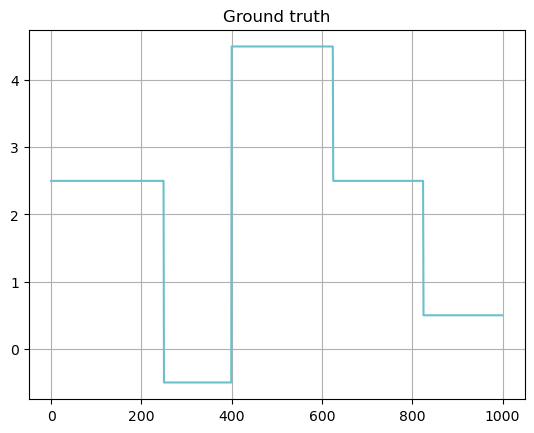

In [3]:
plt.plot(ground_truth)
plt.title("Ground truth")
plt.grid()
plt.show()

In [4]:
# Black box operator for DCT
from jlinops import _CustomLinearOperator

class DCT1D(_CustomLinearOperator):
    """Implements a 1D dct
    """

    def __init__(self, n, type=2, norm="ortho", device="cpu"):
        
        self.type = type
        self.n_size = n
        self.norm = norm


        def _matvec(x):
            return dct(np.squeeze(x), type=self.type, norm=self.norm)
        
        def _rmatvec(x):
            return idct(np.squeeze(x), type=self.type, norm=self.norm)
        
        super().__init__( (n,n), _matvec, _rmatvec, device=device, dtype=None)


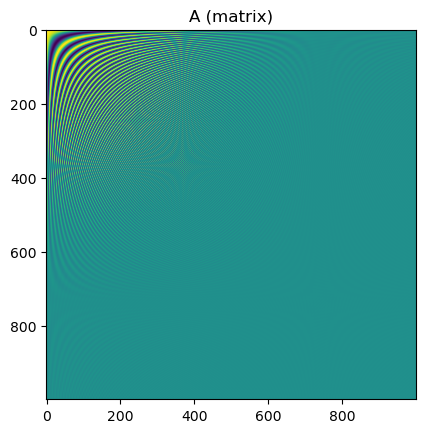

In [5]:
F = DCT1D(n)
F_explicit = jlinops.black_box_to_dense(F)

plt.imshow(F_explicit)
plt.title("A (matrix)")
plt.show()

In [6]:
# Only first 50 components
mask = np.ones(n)
mask[50:] = 0.0
P = jlinops.Subsampling1DOperator(mask)

In [7]:
# Generate synthetic data
np.random.seed(0)
A = P @ F
b_true = A @ ground_truth
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.03
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
#noise_sigma = 0.01*np.amax(b_true)
#noise_var = noise_sigma**2
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

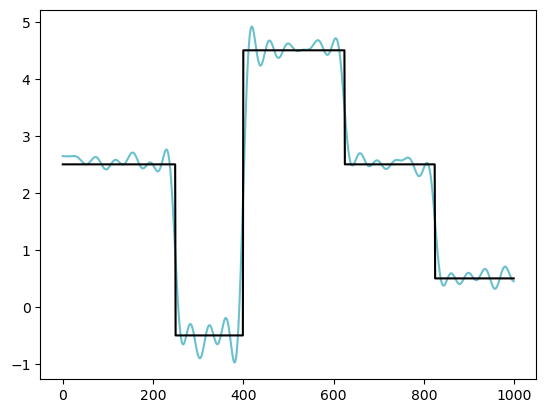

In [8]:
# Inverse DCT reconstruction
plt.plot(A.T @ b)
plt.plot(ground_truth, color="k")
plt.show()

# Setup prior

In [27]:
# Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="zero")
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="none")
Kmat = Kmat/np.linalg.norm(Kmat)
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
# K = None
K = jlinops.MatrixLinearOperator(Kmat)

AK = A @ K.A
AKpinv = jlinops.QRPinvOperator(AK)
xker = K @ (AKpinv @ b)

# xker = None

#_Lpinv = jlinops.BandedCholeskyInvOperator( jlinops.MatrixLinearOperator(L.A.T @ L.A) ) @ L.T 
# _Lpinv = jlinops.MatrixLinearOperator(np.linalg.inv(L.A.toarray()))
_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))
Lpinv_factory2 = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

#Lpinv_factory3 = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/np.sqrt(wr)))
Lpinv_factory3 = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

mm_weight_params = {
    "q": 1.0,
}

iasgks_weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}


In [28]:
L.A.toarray()

array([[ 1., -1.,  0., ...,  0.,  0.,  0.],
       [ 0.,  1., -1., ...,  0.,  0.,  0.],
       [ 0.,  0.,  1., ...,  0.,  0.,  0.],
       ...,
       [ 0.,  0.,  0., ..., -1.,  0.,  0.],
       [ 0.,  0.,  0., ...,  1., -1.,  0.],
       [ 0.,  0.,  0., ...,  0.,  1., -1.]])

# Setup solvers

In [11]:
# Vanilla GKS
v_gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

# MM weights
mm1_gks_solver = MM1GKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mm2_gks_solver = MM2GKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mm3_gks_solver = MM3GKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mmx_gks_solver = MMXGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mm3_fgk_solver = MM3FGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory3, K=K)
# mm4_fgk2019_solver = MM4FGK2019(A, L, _Lpinv, b, noise_var=noise_var, K=K) # Options I, R, W
# mm2_fgkirw_solver = MM2FGKIRW(A, L, _Lpinv, b, noise_var=noise_var, K=K) # Option IRW
mm3_psgkb_solver = MM3GKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mmx_psgkb_solver = MMXGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

# IAS weights
ias_gks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
ias_fgk_solver = IASFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory3, K=K)
# ias_fgk2019_solver = IASFGK2019(A, L, _Lpinv, b, noise_var=noise_var, K=K)
ias_psgkb_solver = IASGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
# ias_fgkirw_solver = IASFGKIRW(A, L, _Lpinv, b, noise_var=noise_var, K=K) # Option IRW

# Solve using all methods

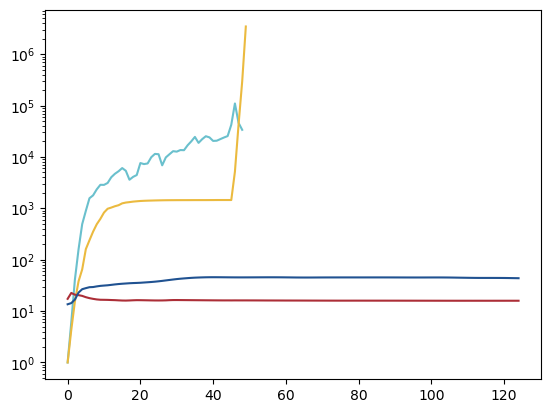

In [50]:
plt.semilogy(mm_fgk_data["cond_ests"])
plt.semilogy(ias_fgk_data["cond_ests"])
plt.semilogy(mm_psgks_data["cond_ests"])
plt.semilogy(mm_sgks_data["cond_ests"])

In [34]:
# Parameters
method = "dp"
n_its = 125
ksparsity = None
lambdah_min = 1e-7
lambdah_max = 1e7

fgk_breakdown_tol = 1e-15

In [35]:
np.__version__

'1.26.3'

In [36]:
%%capture 

### MM weights (2019 version)

all_v_results = []

# Vanilla GKS
v_gks_data = v_gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, weight_params={}, ksparsity=ksparsity,
                                    regparam_kwargs={"eta":1.01},  xker=xker)

all_v_results.append( ( "V", "GKS", v_gks_data  ) )


all_mm_results = []

# S-GKS
mm_sgks_data = mm2_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)

all_mm_results.append( ( "MM", "S-GKS", mm_sgks_data  ) )



# Recycled/restarted S-GKS
mm_sgks_resdata = mm1_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=4, weight_params=mm_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=60)


mm_sgks_recdata = mmx_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=30, max_dim=60, xker=xker, restart_dim=None)


# PS-GKS
mm_psgks_data = mmx_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, 
                                                 regparam_kwargs={"eta":1.01})

all_mm_results.append( ( "MM", "PS-GKS", mm_psgks_data  ) )


# PS-GKB
mm_psgkb_data = mmx_psgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "PS-GKB", mm_psgkb_data  ) )


# FGK
mm_fgk_data = mm3_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, 
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 )

all_mm_results.append( ( "MM", "FGK", mm_fgk_data  ) )



# # FGK2019 (there are three versions to do here.)
# mm_fgk2019I_data = mm4_fgk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
#                                                  regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
#                                                 #  regparam_kwargs={"eta":1.01},
#                                                  lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                                 #  init_dim=5
#                                                  )

# all_mm_results.append( ( "MM", "FLSQR-I", mm_fgk2019I_data  ) )


# mm_fgk2019R_data = mm4_fgk2019_solver.solve(n_iter=n_its, mode="R", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
#                                                  regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
#                                                 #  regparam_kwargs={"eta":1.01},
#                                                  lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                                 #  init_dim=5
#                                                  )

# all_mm_results.append( ( "MM", "FLSQR-R", mm_fgk2019R_data  ) )

# mm_fgk2019W_data = mm4_fgk2019_solver.solve(n_iter=n_its, mode="W", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
#                                                  regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
#                                                 #  regparam_kwargs={"eta":1.01},
#                                                  lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                                 #  init_dim=5
#                                                  )

# all_mm_results.append( ( "MM", "FLSQR-W", mm_fgk2019W_data  ) )

# mm_fgk2019IRW_data = mm2_fgkirw_solver.solve(n_iter=n_its, mode="IRW", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
#                                                  regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
#                                                 #  regparam_kwargs={"eta":1.01},
#                                                  lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                                 #  init_dim=5
#                                                  )

# all_mm_results.append( ( "MM", "IRW-FLSQR", mm_fgk2019IRW_data  ) )


In [37]:
%%capture 

### IAS weights


all_ias_results = []

# S-GKS
ias_sgks_data = ias_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)

all_ias_results.append( ( "IAS", "S-GKS", ias_sgks_data  ) )



# Recycled/restarted S-GKS
ias_sgks_resdata = ias_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=4, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=60)


ias_sgks_recdata = ias_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=30, max_dim=60, xker=xker, restart_dim=None)


# PS-GKS
ias_psgks_data = ias_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, 
                                                 regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "PS-GKS", ias_psgks_data  ) )


ias_psgkb_data = ias_psgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "PS-GKB", ias_psgkb_data  ) )


# FGK
ias_fgk_data = ias_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, 
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 )

all_ias_results.append( ( "IAS", "FGK", ias_fgk_data  ) )



# # FGK2019 (there are four versions to do here.)
# ias_fgk2019I_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
#                                                  regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
#                                                 #  regparam_kwargs={"eta":1.01},
#                                                  lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                                 #  init_dim=5
#                                                  )

# all_ias_results.append( ( "IAS", "FLSQR-I", ias_fgk2019I_data  ) )


# ias_fgk2019R_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="R", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
#                                                  regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
#                                                 #  regparam_kwargs={"eta":1.01},
#                                                  lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                                 #  init_dim=5
#                                                  )

# all_ias_results.append( ( "IAS", "FLSQR-R", ias_fgk2019R_data  ) )

# ias_fgk2019W_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="W", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
#                                                  regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
#                                                 #  regparam_kwargs={"eta":1.01},
#                                                  lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                                 #  init_dim=5
#                                                  )

# all_ias_results.append( ( "IAS", "FLSQR-W", mm_fgk2019W_data  ) )

# ias_fgk2019IRW_data = ias_fgkirw_solver.solve(n_iter=n_its, mode="IRW", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
#                                                  regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
#                                                 #  regparam_kwargs={"eta":1.01},
#                                                  lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                                 #  init_dim=5
#                                                  )

# all_ias_results.append( ( "IAS", "IRW-FLSQR", ias_fgk2019IRW_data  ) )


# Save and make tables

In [38]:
# v_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": [], "n_iters": []})

# for set in all_v_results:
#         weight_str, method_label, method_data = set
#         new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ], "n_iters": [ method_data["n_completed_iterations"] ]   })
#         v_df = pd.concat([v_df, new_df], axis=0)


# mm_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": [], "n_iters": []})

# for set in all_mm_results:
#         weight_str, method_label, method_data = set
#         new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ],  "n_iters": [ method_data["n_completed_iterations"] ] })
#         mm_df = pd.concat([mm_df, new_df], axis=0)



# ias_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": []})

# for set in all_ias_results:
#         weight_str, method_label, method_data = set
#         new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ],  "n_iters": [ method_data["n_completed_iterations"] ] })
#         ias_df = pd.concat([ias_df, new_df], axis=0)

In [39]:
v_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "A matvecs": [], "L matvecs": [], "WLpinv matvecs": [], "n_iters": []  })

for set in all_v_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "A matvecs": [ method_data["tot_matvec_A"] ], "L matvecs": [ method_data["tot_matvec_L"] ], "WLpinv matvecs": [ method_data["tot_matvec_WLpinv"] ], "n_iters": [ method_data["n_completed_iterations"] ]  })
        v_df = pd.concat([v_df, new_df], axis=0)


mm_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": [], "A matvecs": [], "L matvecs": [], "WLpinv matvecs": []})

for set in all_mm_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ], "A matvecs": [ method_data["tot_matvec_A"] ], "L matvecs": [ method_data["tot_matvec_L"] ], "WLpinv matvecs": [ method_data["tot_matvec_WLpinv"] ], "n_iters": [ method_data["n_completed_iterations"] ]  })
        mm_df = pd.concat([mm_df, new_df], axis=0)



ias_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": [], "A matvecs": [], "L matvecs": [], "WLpinv matvecs": []})

for set in all_ias_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ], "A matvecs": [ method_data["tot_matvec_A"] ], "L matvecs": [ method_data["tot_matvec_L"] ], "WLpinv matvecs": [ method_data["tot_matvec_WLpinv"] ], "n_iters": [ method_data["n_completed_iterations"] ] })
        ias_df = pd.concat([ias_df, new_df], axis=0)

In [40]:
all_df = pd.concat([v_df, mm_df, ias_df])
all_df = all_df[["Weights", "Method", "lambdah", "n_iters", "RRE", "SSIM", "Gini index", "A matvecs", "L matvecs", "WLpinv matvecs"]]
all_df = all_df.rename(columns={'lambdah': '$\lambda$', "n_iters":"$n_{\\textrm{iter}}$", "A matvecs":"$n_{\mathbf{A}}$", "L matvecs":"$n_{\mathbf{L}}$", "WLpinv matvecs":"$n_{\mathbf{ L }_k^\dagger }$"  })
#all_df.to_csv("1d_cosine_performance_results.csv")
all_df

,Weights,Method,$\lambda$,$n_{\textrm{iter}}$,RRE,SSIM,Gini index,$n_{\mathbf{A}}$,$n_{\mathbf{L}}$,$n_{\mathbf{ L }_k^\dagger }$
0,V,GKS,1.897075e+02,125.0,0.112112,0.915023,0.671530,265.0,380.0,0.0
0,MM,S-GKS,3.695547e+01,125.0,0.082309,0.950249,0.833820,265.0,381.0,0.0
0,MM,PS-GKS,5.414374e+01,125.0,0.060749,0.971277,0.936692,17011.0,128.0,17135.0
0,MM,PS-GKB,5.413328e+01,125.0,0.060800,0.971219,0.936643,15753.0,126.0,15875.0
0,MM,FGK,3.465169e+01,49.0,0.083221,0.950925,0.930132,103.0,101.0,100.0
0,IAS,S-GKS,2.468386e+02,125.0,0.072730,0.957604,0.789198,265.0,381.0,0.0
0,IAS,PS-GKS,1.000000e+07,125.0,0.075628,0.977197,0.996802,17011.0,128.0,17135.0
0,IAS,PS-GKB,2.657361e+06,125.0,0.049597,0.983196,0.996538,15753.0,126.0,15875.0
0,IAS,FGK,2.040270e+02,50.0,0.103819,0.928230,0.743086,105.0,103.0,102.0


In [41]:
all_df = pd.concat([v_df, mm_df, ias_df])
all_df = all_df[["Weights", "Method", "lambdah", "n_iters", "RRE", "SSIM", "Gini index", "A matvecs", "L matvecs", "WLpinv matvecs"]]
all_df = all_df.rename(columns={'lambdah': '$\lambda$', "n_iters":"$n_{\\textrm{iter}}$", "A matvecs":"$n_{\mathbf{A}}$", "L matvecs":"$n_{\mathbf{L}}$", "WLpinv matvecs":"$n_{\mathbf{ L }_k^\dagger }$"  })
#all_df.to_csv("1d_cosine_performance_results.csv")
all_df

,Weights,Method,$\lambda$,$n_{\textrm{iter}}$,RRE,SSIM,Gini index,$n_{\mathbf{A}}$,$n_{\mathbf{L}}$,$n_{\mathbf{ L }_k^\dagger }$
0,V,GKS,1.897075e+02,125.0,0.112112,0.915023,0.671530,265.0,380.0,0.0
0,MM,S-GKS,3.695547e+01,125.0,0.082309,0.950249,0.833820,265.0,381.0,0.0
0,MM,PS-GKS,5.414374e+01,125.0,0.060749,0.971277,0.936692,17011.0,128.0,17135.0
0,MM,PS-GKB,5.413328e+01,125.0,0.060800,0.971219,0.936643,15753.0,126.0,15875.0
0,MM,FGK,3.465169e+01,49.0,0.083221,0.950925,0.930132,103.0,101.0,100.0
0,IAS,S-GKS,2.468386e+02,125.0,0.072730,0.957604,0.789198,265.0,381.0,0.0
0,IAS,PS-GKS,1.000000e+07,125.0,0.075628,0.977197,0.996802,17011.0,128.0,17135.0
0,IAS,PS-GKB,2.657361e+06,125.0,0.049597,0.983196,0.996538,15753.0,126.0,15875.0
0,IAS,FGK,2.040270e+02,50.0,0.103819,0.928230,0.743086,105.0,103.0,102.0


In [21]:
def scientific_to_latex(sci_str):
    # Split the number into base and exponent parts
    sci_str = f"{sci_str:.0e}"
    base, exponent = sci_str.split('e')
    
    # Convert base to integer (since the decimal places can be ignored)
    base = str(int(float(base)))
    
    # Prepare the exponent part, removing the leading "+" if it's a positive exponent
    exponent = exponent.lstrip("+")
    
    # Format the result as a LaTeX string
    latex_str = f"${base}\\cdot10^{{{int(exponent)}}}$"
    
    return latex_str

In [22]:
print( all_df.to_latex(index=False, formatters={'$\lambda$': lambda s: scientific_to_latex(s), 
                                                "RRE": "${:.3f}$", "SSIM": "${:.3f}$", 
                                                  "Gini index": "${:.3f}$", "Hoyer index": "${:.3f}$", 
                                                  "$n_{\\textrm{iter}}$": "${:.0f}$",
                                                  "$n_{\mathbf{A}}$": "${:.0f}$", "$n_{\mathbf{L}}$": "${:.0f}$", "$n_{\mathbf{ L }_k^\dagger }$": "${:.0f}$"
                                                    }) )

\begin{tabular}{llrrrrrrrr}
\toprule
Weights & Method & $\lambda$ & $n_{\textrm{iter}}$ & RRE & SSIM & Gini index & $n_{\mathbf{A}}$ & $n_{\mathbf{L}}$ & $n_{\mathbf{ L }_k^\dagger }$ \\
\midrule
V & GKS & $2\cdot10^{2}$ & $125$ & $0.112$ & $0.915$ & $0.672$ & $265$ & $380$ & $0$ \\
MM & S-GKS & $4\cdot10^{1}$ & $125$ & $0.082$ & $0.950$ & $0.834$ & $265$ & $381$ & $0$ \\
MM & PS-GKS & $5\cdot10^{1}$ & $125$ & $0.061$ & $0.971$ & $0.937$ & $17011$ & $128$ & $17135$ \\
MM & PS-GKB & $5\cdot10^{1}$ & $125$ & $0.061$ & $0.971$ & $0.937$ & $15753$ & $126$ & $15875$ \\
MM & FGK & $3\cdot10^{1}$ & $49$ & $0.083$ & $0.951$ & $0.930$ & $103$ & $101$ & $100$ \\
IAS & S-GKS & $2\cdot10^{2}$ & $125$ & $0.073$ & $0.958$ & $0.789$ & $265$ & $381$ & $0$ \\
IAS & PS-GKS & $1\cdot10^{7}$ & $125$ & $0.076$ & $0.977$ & $0.997$ & $17011$ & $128$ & $17135$ \\
IAS & PS-GKB & $3\cdot10^{6}$ & $125$ & $0.050$ & $0.983$ & $0.997$ & $15753$ & $126$ & $15875$ \\
IAS & FGK & $2\cdot10^{2}$ & $50$ & $0.104$ & $0.

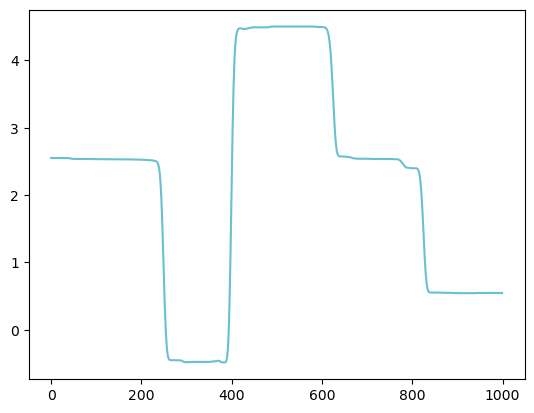

In [23]:
plt.plot(mm_fgk_data["x"])
plt.show()

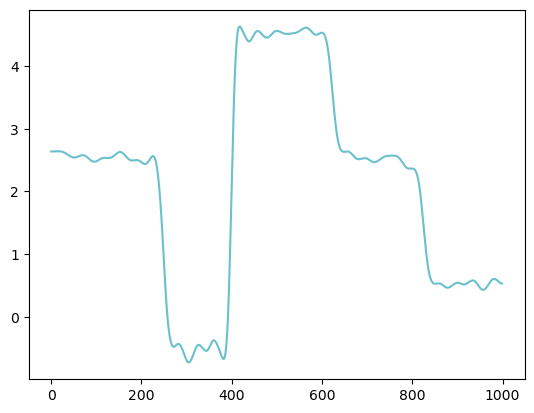

In [24]:
plt.plot(ias_fgk_data["x"])
plt.show()

# Plots for numerics section

## Plotting the solutions

In [25]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
import matplotlib.patches as patches

/var/folders/fn/xbs7g2ln57x3xrdggzf_dzzm0000gr/T/ipykernel_78000/695942150.py:207: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


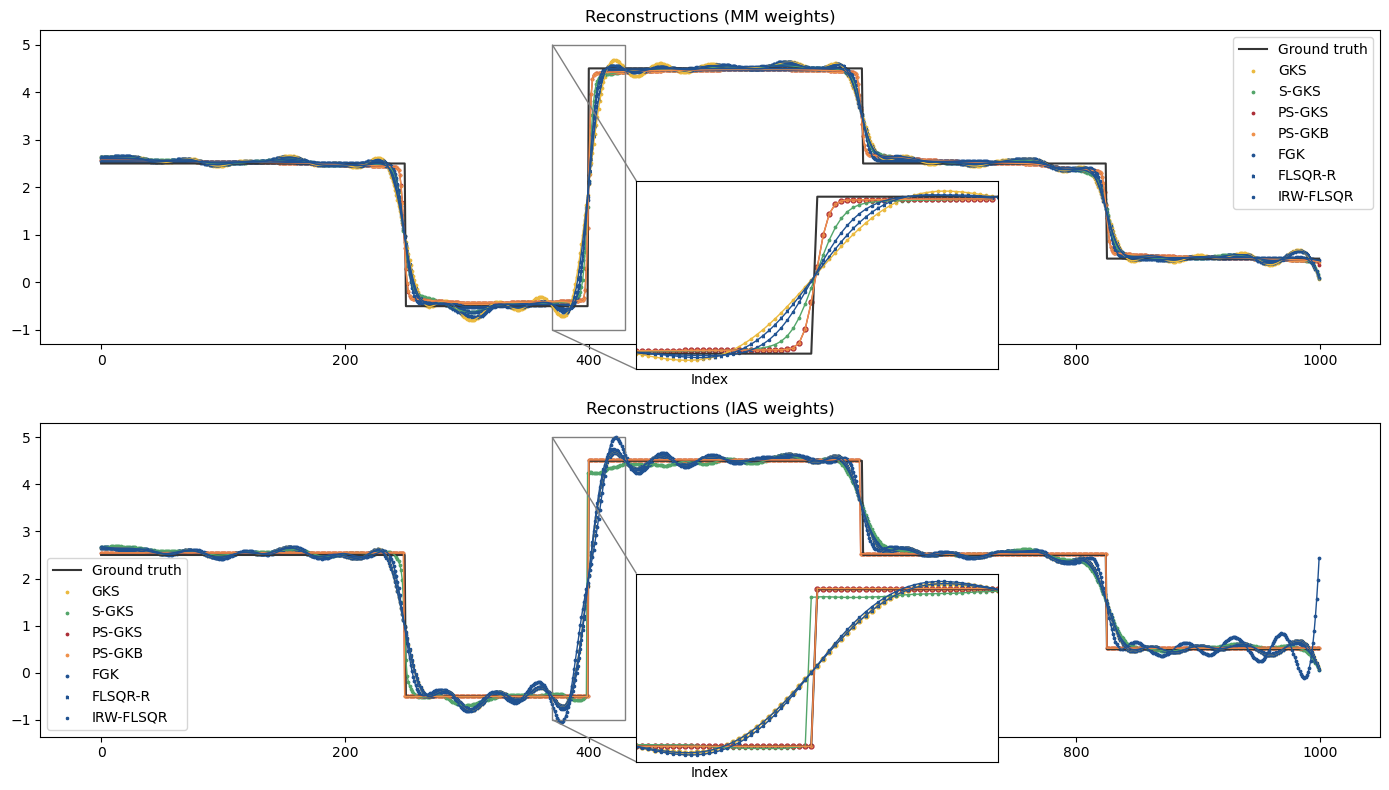

In [25]:
marker_size = 3.0
line_width = 1.0


fig, axs = plt.subplots(2,1,figsize=(14,8))



plot_idx = 0
grid = [i for i in range(len(v_gks_data["x"]))]

# Plot main axs

axs[plot_idx].plot(grid, ground_truth, color="C9", label="Ground truth")

method = "GKS"
axs[plot_idx].plot( grid, v_gks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width )
axs[plot_idx].scatter( grid, v_gks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method  )

method = "S-GKS"
axs[plot_idx].plot( grid, mm_sgks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, mm_sgks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)

method = "PS-GKS"
axs[plot_idx].plot( grid, mm_psgks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, mm_psgks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)

method = "PS-GKB"
axs[plot_idx].plot( grid, mm_psgkb_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, mm_psgkb_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)



method = "FGK"
axs[plot_idx].plot( grid, mm_fgk_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, mm_fgk_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)


method = "FLSQR-R"
axs[plot_idx].plot( grid, mm_fgk2019R_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, mm_fgk2019R_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)


method = "IRW-FLSQR"
axs[plot_idx].plot( grid, mm_fgk2019IRW_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, mm_fgk2019IRW_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)

axs[plot_idx].legend()
axs[plot_idx].set_title("Reconstructions (MM weights)")
axs[plot_idx].set_xlabel("Index")

# Do inset axs
inset_ax = inset_axes(axs[plot_idx], width="30%", height="30%", bbox_to_anchor=(0.13, -0.78, 0.9, 2.0), # _, _, width, height
                      bbox_transform=axs[plot_idx].transAxes, loc='center')

start_idx, stop_idx = 400-30, 400+30
zoom_xlim = [start_idx, stop_idx]
zoom_ylim = [-1, 5]
inset_ax.set_xlim(zoom_xlim)
inset_ax.set_ylim(zoom_ylim)
inset_ax.set_xticks([])
inset_ax.set_yticks([])
# inset_ax.set_title('Inset')
rect = patches.Rectangle((zoom_xlim[0], zoom_ylim[0]),
                         zoom_xlim[1] - zoom_xlim[0],  # Width of the rectangle
                         zoom_ylim[1] - zoom_ylim[0],  # Height of the rectangle
                         linewidth=0.5, edgecolor='gray', facecolor='none', linestyle='--')
axs[plot_idx].add_patch(rect)
mark_inset(axs[plot_idx], inset_ax, loc1=2, loc2=3, fc="none", ec="0.5")


inset_ax.plot(grid, ground_truth, color="C9", label="Ground truth")

method = "GKS"
inset_ax.plot( grid[start_idx:stop_idx], v_gks_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], lw=line_width )
inset_ax.scatter( grid[start_idx:stop_idx], v_gks_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method  )

method = "S-GKS"
inset_ax.plot( grid[start_idx:stop_idx], mm_sgks_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid[start_idx:stop_idx], mm_sgks_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)

method = "PS-GKS"
inset_ax.plot( grid[start_idx:stop_idx], mm_psgks_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid[start_idx:stop_idx], mm_psgks_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=4*marker_size , label=method)

method = "PS-GKB"
inset_ax.plot( grid[start_idx:stop_idx], mm_psgkb_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid[start_idx:stop_idx], mm_psgkb_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)


method = "FLSQR-R"
inset_ax.plot( grid, mm_fgk2019R_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid, mm_fgk2019R_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)



method = "IRW-FLSQR"
inset_ax.plot( grid[start_idx:stop_idx], mm_fgk2019IRW_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid[start_idx:stop_idx], mm_fgk2019IRW_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)







plot_idx = 1

axs[plot_idx].plot(grid, ground_truth, color="C9", label="Ground truth")

method = "GKS"
axs[plot_idx].plot( grid, v_gks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, v_gks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method )

method = "S-GKS"
axs[plot_idx].plot( grid, ias_sgks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, ias_sgks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)


method = "PS-GKS"
axs[plot_idx].plot( grid, ias_psgks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, ias_psgks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)

method = "PS-GKB"
axs[plot_idx].plot( grid, ias_psgkb_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, ias_psgkb_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)


method = "FGK"
axs[plot_idx].plot( grid, ias_fgk_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, ias_fgk_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)


method = "FLSQR-R"
axs[plot_idx].plot( grid, ias_fgk2019R_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, ias_fgk2019R_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)



method = "IRW-FLSQR"
axs[plot_idx].plot( grid, ias_fgk2019IRW_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, ias_fgk2019IRW_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)




# Do inset axs
inset_ax = inset_axes(axs[plot_idx], width="30%", height="30%", bbox_to_anchor=(0.13, -0.78, 0.9, 2.0), # _, _, width, height
                      bbox_transform=axs[plot_idx].transAxes, loc='center')

start_idx, stop_idx = 400-30, 400+30
zoom_xlim = [start_idx, stop_idx]
zoom_ylim = [-1, 5]
inset_ax.set_xlim(zoom_xlim)
inset_ax.set_ylim(zoom_ylim)
inset_ax.set_xticks([])
inset_ax.set_yticks([])
# inset_ax.set_title('Inset')
rect = patches.Rectangle((zoom_xlim[0], zoom_ylim[0]),
                         zoom_xlim[1] - zoom_xlim[0],  # Width of the rectangle
                         zoom_ylim[1] - zoom_ylim[0],  # Height of the rectangle
                         linewidth=0.5, edgecolor='gray', facecolor='none', linestyle='--')
axs[plot_idx].add_patch(rect)
mark_inset(axs[plot_idx], inset_ax, loc1=2, loc2=3, fc="none", ec="0.5")

inset_ax.plot(grid, ground_truth, color="C9", label="Ground truth")


method = "GKS"
inset_ax.plot( grid, v_gks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid, v_gks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=4*marker_size , label=method )

method = "S-GKS"
inset_ax.plot( grid, ias_sgks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid, ias_sgks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)


method = "PS-GKS"
inset_ax.plot( grid, ias_psgks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid, ias_psgks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=4*marker_size , label=method)

method = "PS-GKB"
inset_ax.plot( grid, ias_psgkb_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid, ias_psgkb_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)



method = "FLSQR-R"
inset_ax.plot( grid, ias_fgk2019R_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid, ias_fgk2019R_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)



method = "IRW-FLSQR"
inset_ax.plot( grid, ias_fgk2019IRW_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid, ias_fgk2019IRW_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)





axs[plot_idx].legend()
axs[plot_idx].set_title("Reconstructions (IAS weights)")
axs[plot_idx].set_xlabel("Index")


fig.tight_layout()
#fig.savefig("1d_cosine_reconstructions.png", dpi=250, bbox_inches="tight")
#fig.savefig("1d_cosine_reconstructions.eps", format="eps", dpi=250, bbox_inches="tight")

plt.show()

## Plotting metrics

In [26]:
# metric = "gini_indices"
# #metric = "hoyer_indices"
# # metric = "rre_history"
# start_idx = 5
# marker_size = 10.0
# line_width = 1.0

# fig, axs = plt.subplots(2,3,figsize=(14,8))


# # First plot
# plot_idx = (0,0)
# plot_title = "RRE history (MM weights)"
# metric = "rre_history"

# method = "GKS"
# grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
# axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

# method = "S-GKS"
# grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
# axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

# method = "PS-GKS"
# grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
# axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

# method = "PS-GKB"
# grid = [i for i in range(start_idx, len(mm_psgkb_data[metric]))]
# axs[plot_idx].plot( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "FGK"
# grid = [i for i in range(start_idx, len(mm_fgk_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# # method = "FLSQR-W"
# # grid = [i for i in range(start_idx, len(mm_fgk2019W_data[metric]))]
# # axs[plot_idx].plot( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# # axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)



# # method = "FLSQR-I"
# # grid = [i for i in range(start_idx, len(mm_fgk2019I_data[metric]))]
# # axs[plot_idx].plot( grid, mm_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# # axs[plot_idx].scatter( grid, mm_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# # method = "FLSQR-R"
# # grid = [i for i in range(start_idx, len(mm_fgk2019R_data[metric]))]
# # axs[plot_idx].plot( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# # axs[plot_idx].scatter( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)



# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(mm_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# axs[plot_idx].set_xlabel("Iteration index")
# axs[plot_idx].legend()
# axs[plot_idx].set_title(plot_title)




# # First plot
# plot_idx = (1,0)
# plot_title = "RRE history (IAS weights)"
# metric = "rre_history"

# method = "GKS"
# grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
# axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

# method = "S-GKS"
# grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
# axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

# method = "PS-GKS"
# grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
# axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

# method = "PS-GKB"
# grid = [i for i in range(start_idx, len(ias_psgkb_data[metric]))]
# axs[plot_idx].plot( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "FGK"
# grid = [i for i in range(start_idx, len(ias_fgk_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# # method = "FLSQR-W"
# # grid = [i for i in range(start_idx, len(ias_fgk2019W_data[metric]))]
# # axs[plot_idx].plot( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# # axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# # method = "FLSQR-I"
# # grid = [i for i in range(start_idx, len(ias_fgk2019I_data[metric]))]
# # axs[plot_idx].plot( grid, ias_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# # axs[plot_idx].scatter( grid, ias_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)

# # method = "FLSQR-R"
# # grid = [i for i in range(start_idx, len(ias_fgk2019R_data[metric]))]
# # axs[plot_idx].plot( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# # axs[plot_idx].scatter( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)




# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(ias_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# axs[plot_idx].set_xlabel("Iteration index")
# axs[plot_idx].legend()
# axs[plot_idx].set_title(plot_title)









# # First plot
# plot_idx = (0,1)
# plot_title = "SSIM history (MM weights)"
# metric = "ssim_history"

# method = "GKS"
# grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
# axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

# method = "S-GKS"
# grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
# axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

# method = "PS-GKS"
# grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
# axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

# method = "PS-GKB"
# grid = [i for i in range(start_idx, len(mm_psgkb_data[metric]))]
# axs[plot_idx].plot( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "FGK"
# grid = [i for i in range(start_idx, len(mm_fgk_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# # method = "FLSQR-W"
# # grid = [i for i in range(start_idx, len(mm_fgk2019W_data[metric]))]
# # axs[plot_idx].plot( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# # axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)



# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(mm_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# axs[plot_idx].set_xlabel("Iteration index")
# axs[plot_idx].legend()
# axs[plot_idx].set_title(plot_title)




# # First plot
# plot_idx = (1,1)
# plot_title = "SSIM history (IAS weights)"
# metric = "ssim_history"

# method = "GKS"
# grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
# axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

# method = "S-GKS"
# grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
# axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

# method = "PS-GKS"
# grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
# axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

# method = "PS-GKB"
# grid = [i for i in range(start_idx, len(ias_psgkb_data[metric]))]
# axs[plot_idx].plot( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "FGK"
# grid = [i for i in range(start_idx, len(ias_fgk_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# # method = "FLSQR-W"
# # grid = [i for i in range(start_idx, len(ias_fgk2019W_data[metric]))]
# # axs[plot_idx].plot( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# # axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)



# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(ias_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# axs[plot_idx].set_xlabel("Iteration index")
# axs[plot_idx].legend()
# axs[plot_idx].set_title(plot_title)














# # First plot
# plot_idx = (0,2)
# plot_title = "Gini index (MM weights)"
# metric = "gini_indices"

# method = "GKS"
# grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
# axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

# method = "S-GKS"
# grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
# axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

# method = "PS-GKS"
# grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
# axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

# method = "PS-GKB"
# grid = [i for i in range(start_idx, len(mm_psgkb_data[metric]))]
# axs[plot_idx].plot( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "FGK"
# grid = [i for i in range(start_idx, len(mm_fgk_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# # method = "FLSQR-W"
# # grid = [i for i in range(start_idx, len(mm_fgk2019W_data[metric]))]
# # axs[plot_idx].plot( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# # axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)



# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(mm_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# axs[plot_idx].set_xlabel("Iteration index")
# axs[plot_idx].legend()
# axs[plot_idx].set_title(plot_title)




# # First plot
# plot_idx = (1,2)
# plot_title = "Gini index (IAS weights)"
# metric = "gini_indices"

# method = "GKS"
# grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
# axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

# method = "S-GKS"
# grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
# axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

# method = "PS-GKS"
# grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
# axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

# method = "PS-GKB"
# grid = [i for i in range(start_idx, len(ias_psgkb_data[metric]))]
# axs[plot_idx].plot( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "FGK"
# grid = [i for i in range(start_idx, len(ias_fgk_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "FLSQR-W"
# grid = [i for i in range(start_idx, len(ias_fgk2019W_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)



# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(ias_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# axs[plot_idx].set_xlabel("Iteration index")
# axs[plot_idx].legend()
# axs[plot_idx].set_title(plot_title)





# fig.tight_layout()
# # fig.savefig("1d_cosine_performance", dpi=250, bbox_inches=None)
# # fig.savefig("1d_cosine_performance.eps", format="eps", dpi=250, bbox_inches=None)




# plt.show()

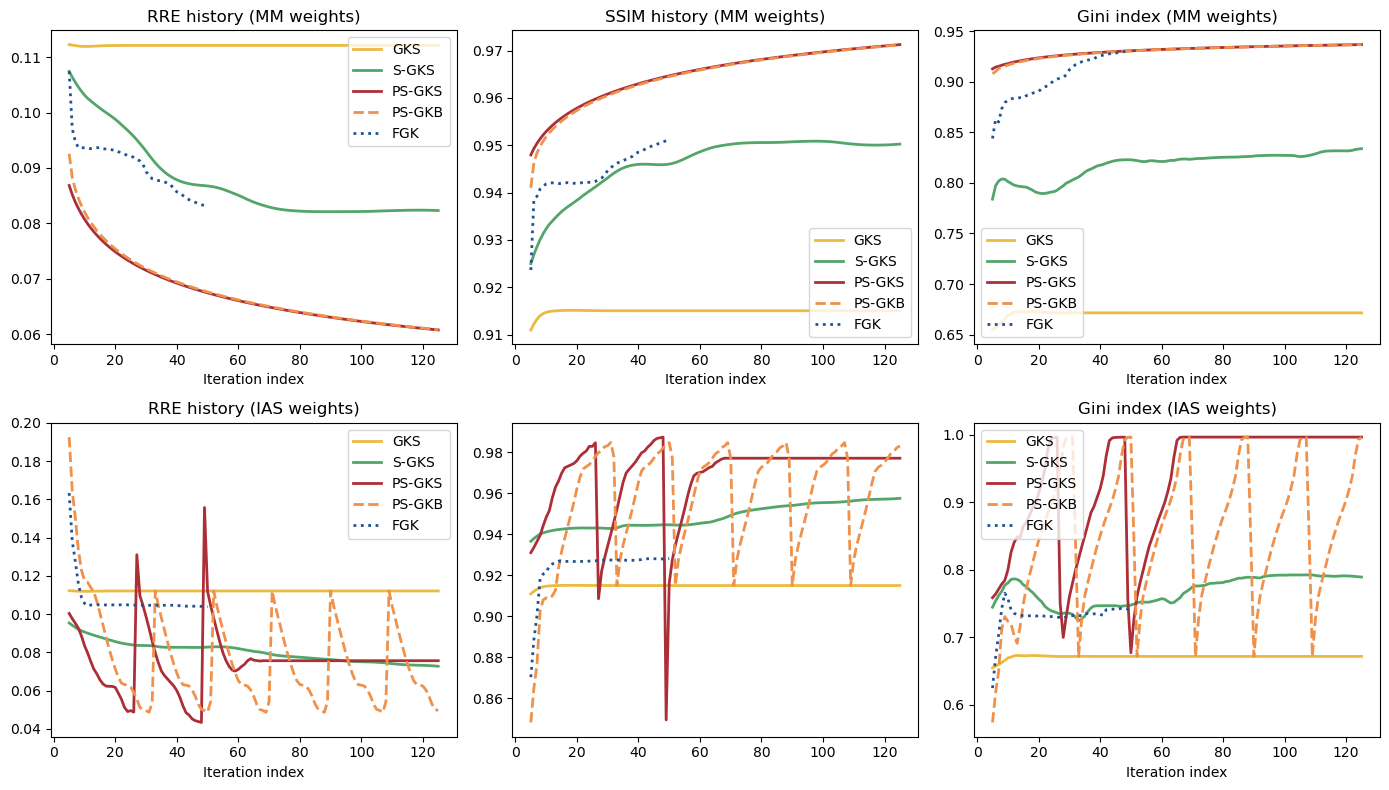

In [42]:
metric = "gini_indices"
#metric = "hoyer_indices"
# metric = "rre_history"
start_idx = 5
marker_size = 10.0
line_width = 2.0


method_lines = {
    "GKS": "solid",
    "S-GKS": "solid",
    "resS-GKS": "dotted",
    "recS-GKS": "dashed",
    "PS-GKS": "solid",
    "resPS-GKS": "dotted",
    "recPS-GKS": "dashed",
    "PS-GKB": "dashed",
    "FGK": "dotted",
    "FLSQR-I": "dotted",
    "FLSQR-R": "dashed",
    "FLSQR-W": "dashdot",
    "IRW-FLSQR": (0, (3, 1, 1, 1, 1, 1)),
}

fig, axs = plt.subplots(2,3,figsize=(14,8))


# First plot
plot_idx = (0,0)
plot_title = "RRE history (MM weights)"
metric = "rre_history"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS"
grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKB"
grid = [i for i in range(start_idx, len(mm_psgkb_data[metric]))]
axs[plot_idx].plot( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(mm_fgk_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(mm_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "FLSQR-R"
# grid = [i for i in range(start_idx, len(mm_fgk2019R_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-W"
# grid = [i for i in range(start_idx, len(mm_fgk2019W_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)



# method = "FLSQR-I"
# grid = [i for i in range(start_idx, len(mm_fgk2019I_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-R"
# grid = [i for i in range(start_idx, len(mm_fgk2019R_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)




axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)




# First plot
plot_idx = (1,0)
plot_title = "RRE history (IAS weights)"
metric = "rre_history"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS"
grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKB"
grid = [i for i in range(start_idx, len(ias_psgkb_data[metric]))]
axs[plot_idx].plot( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(ias_fgk_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(ias_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-R"
# grid = [i for i in range(start_idx, len(ias_fgk2019R_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-W"
# grid = [i for i in range(start_idx, len(ias_fgk2019W_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-I"
# grid = [i for i in range(start_idx, len(ias_fgk2019I_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)









# First plot
plot_idx = (0,1)
plot_title = "SSIM history (MM weights)"
metric = "ssim_history"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS"
grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKB"
grid = [i for i in range(start_idx, len(mm_psgkb_data[metric]))]
axs[plot_idx].plot( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(mm_fgk_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(mm_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "FLSQR-R"
# grid = [i for i in range(start_idx, len(mm_fgk2019R_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-W"
# grid = [i for i in range(start_idx, len(mm_fgk2019W_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)




# First plot
plot_idx = (1,1)
plot_title = "SSIM history (IAS weights)"
metric = "ssim_history"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS"
grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKB"
grid = [i for i in range(start_idx, len(ias_psgkb_data[metric]))]
axs[plot_idx].plot( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(ias_fgk_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(ias_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-R"
# grid = [i for i in range(start_idx, len(ias_fgk2019R_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-W"
# grid = [i for i in range(start_idx, len(ias_fgk2019W_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# axs[plot_idx].set_xlabel("Iteration index")
# axs[plot_idx].legend()
# axs[plot_idx].set_title(plot_title)












# First plot
plot_idx = (0,2)
plot_title = "Gini index (MM weights)"
metric = "gini_indices"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS"
grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKB"
grid = [i for i in range(start_idx, len(mm_psgkb_data[metric]))]
axs[plot_idx].plot( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(mm_fgk_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(mm_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "FLSQR-R"
# grid = [i for i in range(start_idx, len(mm_fgk2019R_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-W"
# grid = [i for i in range(start_idx, len(mm_fgk2019W_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)




axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)




# First plot
plot_idx = (1,2)
plot_title = "Gini index (IAS weights)"
metric = "gini_indices"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS"
grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKB"
grid = [i for i in range(start_idx, len(ias_psgkb_data[metric]))]
axs[plot_idx].plot( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(ias_fgk_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



# method = "IRW-FLSQR"
# grid = [i for i in range(start_idx, len(ias_fgk2019IRW_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)

# method = "FLSQR-R"
# grid = [i for i in range(start_idx, len(ias_fgk2019R_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)

# method = "FLSQR-W"
# grid = [i for i in range(start_idx, len(ias_fgk2019W_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)





axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)





fig.tight_layout()
fig.savefig("1d_cosine_performance", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_performance.eps", format="eps", dpi=250, bbox_inches=None)




plt.show()

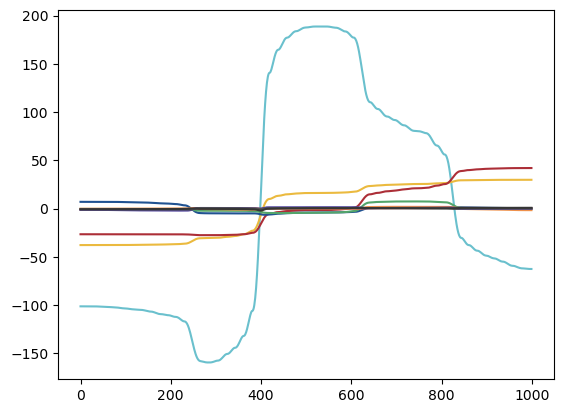

In [45]:
for j in range(10):
    plt.plot(mm_fgk_data["Z"][:,j])
plt.show()

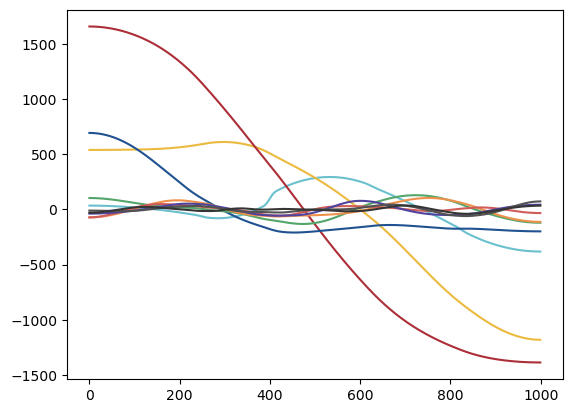

In [46]:
for j in range(10):
    plt.plot(ias_fgk_data["Z"][:,j])
plt.show()

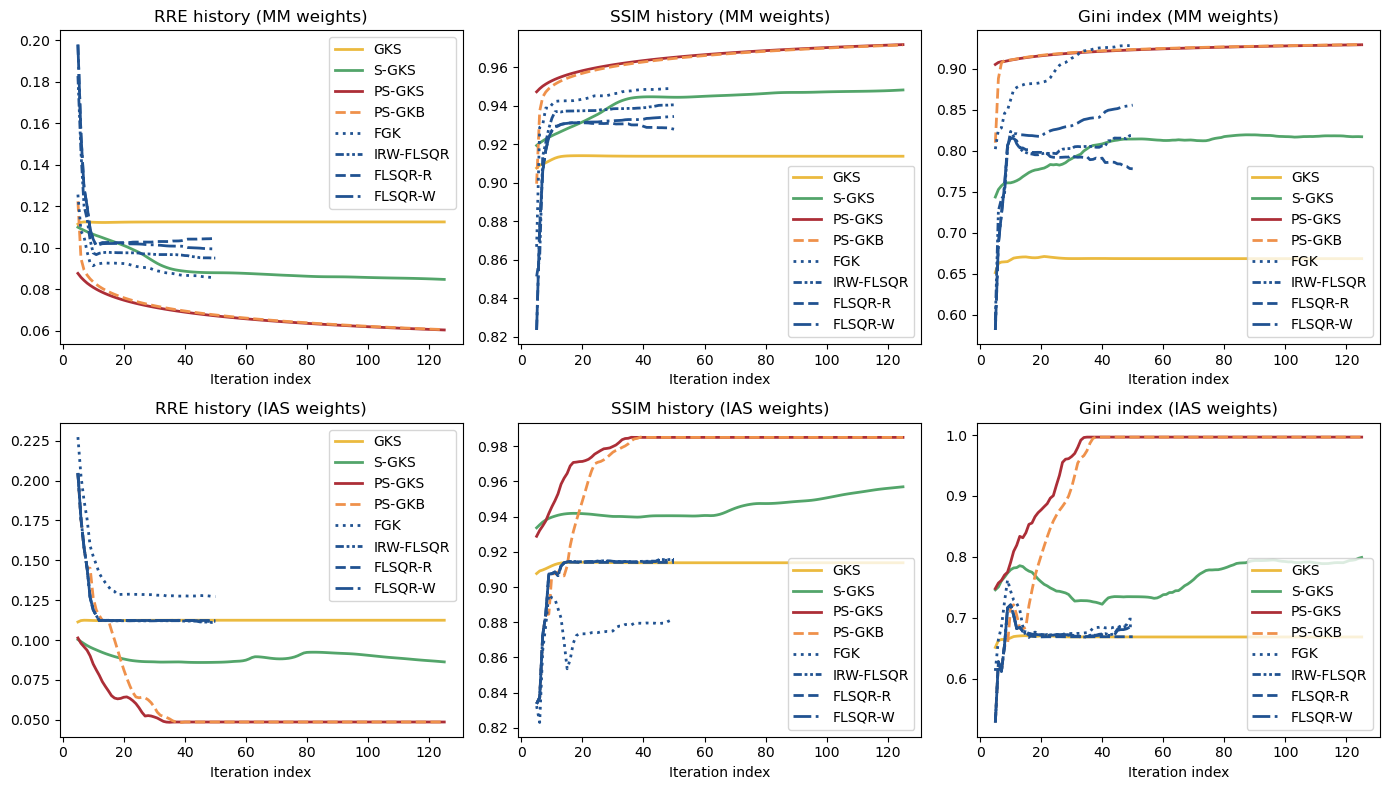

In [27]:
metric = "gini_indices"
#metric = "hoyer_indices"
# metric = "rre_history"
start_idx = 5
marker_size = 10.0
line_width = 2.0


method_lines = {
    "GKS": "solid",
    "S-GKS": "solid",
    "resS-GKS": "dotted",
    "recS-GKS": "dashed",
    "PS-GKS": "solid",
    "resPS-GKS": "dotted",
    "recPS-GKS": "dashed",
    "PS-GKB": "dashed",
    "FGK": "dotted",
    "FLSQR-I": "dotted",
    "FLSQR-R": "dashed",
    "FLSQR-W": "dashdot",
    "IRW-FLSQR": (0, (3, 1, 1, 1, 1, 1)),
}

fig, axs = plt.subplots(2,3,figsize=(14,8))


# First plot
plot_idx = (0,0)
plot_title = "RRE history (MM weights)"
metric = "rre_history"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS"
grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKB"
grid = [i for i in range(start_idx, len(mm_psgkb_data[metric]))]
axs[plot_idx].plot( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(mm_fgk_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "IRW-FLSQR"
grid = [i for i in range(start_idx, len(mm_fgk2019IRW_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FLSQR-R"
grid = [i for i in range(start_idx, len(mm_fgk2019R_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


method = "FLSQR-W"
grid = [i for i in range(start_idx, len(mm_fgk2019W_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)



# method = "FLSQR-I"
# grid = [i for i in range(start_idx, len(mm_fgk2019I_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-R"
# grid = [i for i in range(start_idx, len(mm_fgk2019R_data[metric]))]
# axs[plot_idx].plot( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)




axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)




# First plot
plot_idx = (1,0)
plot_title = "RRE history (IAS weights)"
metric = "rre_history"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS"
grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKB"
grid = [i for i in range(start_idx, len(ias_psgkb_data[metric]))]
axs[plot_idx].plot( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(ias_fgk_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



method = "IRW-FLSQR"
grid = [i for i in range(start_idx, len(ias_fgk2019IRW_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


method = "FLSQR-R"
grid = [i for i in range(start_idx, len(ias_fgk2019R_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


method = "FLSQR-W"
grid = [i for i in range(start_idx, len(ias_fgk2019W_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


# method = "FLSQR-I"
# grid = [i for i in range(start_idx, len(ias_fgk2019I_data[metric]))]
# axs[plot_idx].plot( grid, ias_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_fgk2019I_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)









# First plot
plot_idx = (0,1)
plot_title = "SSIM history (MM weights)"
metric = "ssim_history"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS"
grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKB"
grid = [i for i in range(start_idx, len(mm_psgkb_data[metric]))]
axs[plot_idx].plot( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(mm_fgk_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "IRW-FLSQR"
grid = [i for i in range(start_idx, len(mm_fgk2019IRW_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FLSQR-R"
grid = [i for i in range(start_idx, len(mm_fgk2019R_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


method = "FLSQR-W"
grid = [i for i in range(start_idx, len(mm_fgk2019W_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)




# First plot
plot_idx = (1,1)
plot_title = "SSIM history (IAS weights)"
metric = "ssim_history"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS"
grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKB"
grid = [i for i in range(start_idx, len(ias_psgkb_data[metric]))]
axs[plot_idx].plot( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(ias_fgk_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "IRW-FLSQR"
grid = [i for i in range(start_idx, len(ias_fgk2019IRW_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


method = "FLSQR-R"
grid = [i for i in range(start_idx, len(ias_fgk2019R_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


method = "FLSQR-W"
grid = [i for i in range(start_idx, len(ias_fgk2019W_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)












# First plot
plot_idx = (0,2)
plot_title = "Gini index (MM weights)"
metric = "gini_indices"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS"
grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKB"
grid = [i for i in range(start_idx, len(mm_psgkb_data[metric]))]
axs[plot_idx].plot( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(mm_fgk_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



method = "IRW-FLSQR"
grid = [i for i in range(start_idx, len(mm_fgk2019IRW_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FLSQR-R"
grid = [i for i in range(start_idx, len(mm_fgk2019R_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)


method = "FLSQR-W"
grid = [i for i in range(start_idx, len(mm_fgk2019W_data[metric]))]
axs[plot_idx].plot( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)




axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)




# First plot
plot_idx = (1,2)
plot_title = "Gini index (IAS weights)"
metric = "gini_indices"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKS"
grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "PS-GKB"
grid = [i for i in range(start_idx, len(ias_psgkb_data[metric]))]
axs[plot_idx].plot( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgkb_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "FGK"
grid = [i for i in range(start_idx, len(ias_fgk_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



method = "IRW-FLSQR"
grid = [i for i in range(start_idx, len(ias_fgk2019IRW_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk2019IRW_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)

method = "FLSQR-R"
grid = [i for i in range(start_idx, len(ias_fgk2019R_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)

method = "FLSQR-W"
grid = [i for i in range(start_idx, len(ias_fgk2019W_data[metric]))]
axs[plot_idx].plot( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_fgk2019W_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)





axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)





fig.tight_layout()
fig.savefig("1d_cosine_performance", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_performance.eps", format="eps", dpi=250, bbox_inches=None)




plt.show()

# Plotting for initial section

### Reconstructions

In [12]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="zero")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
K = None
xker = None

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.inv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))
Lpinv_factory2 = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))


mm_weight_params = {
    "q": 1.0,
    "epsilon": 1e-3,
}

iasgks_weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}


In [13]:
# Parameters
method = "dp"
n_its = 300
ksparsity = None
lambdah_min = 1e-7
lambdah_max = 1e7


fgk_breakdown_tol = 1e-15

In [14]:
# Vanilla GKS
v_gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

# MM weights
mm_gks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

# IAS weights
ias_gks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

In [33]:
# Vanilla GKS
v_gks_data = v_gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, weight_params={}, ksparsity=ksparsity,
                                    regparam_kwargs={"eta":1.01},  xker=xker)



# S-GKS
mm_sgks_data = mm_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)


mm_resdata = mm_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=4, weight_params=mm_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=40)


mm_recdata = mm_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=20, max_dim=40, xker=xker, restart_dim=None)



# PS-GKS
mm_psgks_data = mm_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, 
                                                 regparam_kwargs={"eta":1.01})




# S-GKS
ias_sgks_data = ias_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)



ias_resdata = ias_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=4, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=40)


ias_recdata = ias_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=20, max_dim=40, xker=xker, restart_dim=None)



# PS-GKS
ias_psgks_data = ias_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, 
                                                 regparam_kwargs={"eta":1.01})




734.4247114348133
773.4913540627327
792.7646435688165
786.7947212547227
678.4096966018841
398.1030990218177
261.6985788419615
222.5772537620482
207.12262435777706
199.1489349912947
194.4712497396449
191.68058160550132
189.98769984019867
188.9407545638505
188.3192580745528
187.93155030095286
187.67406298505784
187.50640959098223
187.3773626339308
187.25679805816196
187.13438220593392
187.03423039306728
186.96873930334675
186.92695705730347
186.90215045553626
186.88283133917605
186.8678029119946
186.86570858542063
186.87507125576715
186.89381598965608
186.91736376635816
186.9370501948805
186.95321071633865
186.96858885412058
186.98339953185004
186.99530261963395
187.005226466949
187.0143463042034
187.02335563902187
187.03179454279942
187.0382934908616
187.0430259484341
187.0470223036739
187.05021945655372
187.0521144980719
187.05344174096933
187.0546805216003
187.05544264799784
187.05577245421875
187.05598119143846
187.0561220229203
187.05598952199165
187.05550868385896
187.0549666846016

10.276081420264262
10.62545129898487
11.462383466292557
12.364877304622427
14.210770867107744
21.048997132333398
20.305901864918017
18.927656664020635
18.884121017000734
17.560326656859758
19.39959210221311
20.515643506698083
21.59179485166167
22.535301041392167
21.504220832438058
20.71539701221811
21.350791916265454
21.664674853828025
21.773782635174786
21.904484998822962
22.348277455582817
22.95144400032613
23.71344507149647
24.818513371084528
25.726471954422273
26.575511711210375
27.329647017977717
27.87347799926827
28.16014269091929
28.511311661561862
28.941678300612505
29.781265512836313
30.5641925880251
30.918368957902526
30.93474550036192
30.731638952672327
30.42724226165872
30.00308554463028
29.67657013725073
29.381102482912553
29.37870111745053
29.689961187701037
30.24781703018465
30.921970883369948
31.507782632073148
32.41368164753271
33.926625136821905
35.95162992225994
38.13814495018369
40.87335728744076
43.66623644051025
46.00700390015904
48.2772529352912
50.37732356764604

10.276081420264262
10.62545129898487
11.462383466292557
12.364877304622427
14.210770867107744
21.048997132333398
20.305901864918017
18.927656664020635
18.884121017000734
17.560326656859758
19.39959210221311
20.515643506698083
21.59179485166167
22.535301041392167
21.504220832438058
20.71539701221811
21.350791916265454
21.664674853828025
21.773782635174786
21.904484998822962
22.348277455582817
22.95144400032613
23.71344507149647
24.818513371084528
25.726471954422273
26.575511711210375
27.329647017977717
27.87347799926827
28.16014269091929
28.511311661561862
28.941678300612505
29.781265512836313
30.5641925880251
30.918368957902526
30.88656195956241
31.753541577515715
33.73360580700749
35.816270412685824
37.60766691166578
38.94099048956769
39.9715045587606
40.725176863641316
41.128047613829516
41.06315533344835
40.22950554516188
38.65064873639643
36.089563043155216
32.821749903684044
28.21215894103012
23.602141935994908
18.861708325563264
16.972303943334527
16.417368627297265
16.6532373928

10.276081420264262
10.62545129898487
11.462383466292557
12.364877304622427
14.210770867107744
21.048997132333398
20.305901864918017
18.927656664020635
18.884121017000734
17.560326656859758
19.39959210221311
20.515643506698083
21.59179485166167
22.535301041392167
21.504220832438058
20.71539701221811
21.350791916265454
21.664674853828025
21.773782635174786
21.904484998822962
22.348277455582817
22.95144400032613
23.71344507149647
24.818513371084528
25.726471954422273
26.575511711210375
27.329647017977717
27.87347799926827
28.16014269091929
28.511311661561862
28.941678300612505
29.781265512836313
30.5641925880251
30.918368957902526
(40, 40)
(40, 40)
(80, 40)
30.892716885774615
32.271238931971695
34.37110178205943
36.48022337068655
38.127429388580936
39.35608049635583
40.28999834095339
40.91645602287801
41.12044172902931
40.699143045707835
39.491856025098436
37.54711978752226
34.47292301561394
30.401186443849287
25.44726171925346
20.325657104230647
17.424638888850996
16.389609783327764
16.3

1e-07


...

1e-07
14.782887939181066
21.850420544402876
27.217218351923414
31.20773490238832
34.19411721150055
36.58756304733694
38.57073307873422
40.190689628177886
41.47041817220344
42.56333974447042
43.48398587246146
44.28169935408282
44.97445625687612
45.58932687150762
46.131156106493364
46.61622389599995
47.05153382140514
47.44554485566918
47.80340488968891
48.13005680151562
48.429333973628346
48.704635794028405
48.95884560649621
49.19435940447175
49.41305277374796
49.616780360451195
49.80705647749309
49.98517161698967
50.152251377425465
50.30937076401425
50.45732528740914
50.59697734505323
50.72897093896684
50.85395370605243
50.972462919767466
51.085002898450256
51.19202580054386
51.29391991470482
51.39106469103914
51.483779523957885
51.572367945725624
51.65710707948242
51.73823993770616
51.81599989016727
51.89059372364451
51.9622159413609
52.0310410333438
52.097235032970595
52.16094551376815
52.22231337036455
52.2814670340716
52.33852536689282
52.393600154450446
52.44679401918141
52.4982031

75.68579716836693
122.13673531129605
151.7216807441078
183.2643390677603
211.19874391496109
232.49654527509114
249.64070643712506
264.11278654089307
275.87194515676094
284.9566526033685
291.1543287208482
294.4445078614029
294.5648428049675
291.76195075144784
286.48782303065445
279.4093318176523
271.36439558177193
263.50264851050554
256.73364774244016
251.37837783223998
247.87220996265685
246.59887966229348
247.06271630776
248.70592717725367
251.54892691907494
255.40598772534324
259.3104339805076
262.601027955546
265.3389945755883
267.80817493575404
270.1790713799948
272.27102608542833
273.64640698930174
274.1070811286186
273.8457300157592
273.3610975251791
272.85536160680005
272.28797644322816
270.98911560327
268.2104188172371
264.2891339711982
260.2324258117908
257.06187936339234
254.595257019008
252.88552083009313
251.8655247184333
251.22620728470108
250.7891557135592
250.56093828828395
250.61190509752606
250.81865980753932
251.00117275900476
251.08227149444897
251.07989182226083
251

75.68579716836693
122.13673531129605
151.7216807441078
183.2643390677603
211.19874391496109
232.49654527509114
249.64070643712506
264.11278654089307
275.87194515676094
284.9566526033685
291.1543287208482
294.4445078614029
294.5648428049675
291.76195075144784
286.48782303065445
279.4093318176523
271.36439558177193
263.50264851050554
256.73364774244016
251.37837783223998
247.87220996265685
246.59887966229348
247.06271630776
248.70592717725367
251.54892691907494
255.40598772534324
259.3104339805076
262.601027955546
265.3389945755883
267.80817493575404
270.1790713799948
272.27102608542833
273.64640698930174
274.1070811286186
273.268288378772
272.76603080770013
274.3599460362258
272.9734296098464
263.05404798498876
250.68250821607583
249.44187487869212
257.89179237943296
266.2757946246125
268.5893269639245
262.5034893281397
254.19909866268858
252.35877713653917
251.01465279797748
249.45776700274632
245.05932758907753
245.60036396726207
258.74173412201685
270.24291147167446
263.3622413236473

75.68579716836693
122.13673531129605
151.7216807441078
183.2643390677603
211.19874391496109
232.49654527509114
249.64070643712506
264.11278654089307
275.87194515676094
284.9566526033685
291.1543287208482
294.4445078614029
294.5648428049675
291.76195075144784
286.48782303065445
279.4093318176523
271.36439558177193
263.50264851050554
256.73364774244016
251.37837783223998
247.87220996265685
246.59887966229348
247.06271630776
248.70592717725367
251.54892691907494
255.40598772534324
259.3104339805076
262.601027955546
265.3389945755883
267.80817493575404
270.1790713799948
272.27102608542833
273.64640698930174
274.1070811286186
(40, 40)
(40, 40)
(80, 40)
273.2743082618517
272.7426373841142
273.3760625316501
271.51564723460183
260.74561716566353
250.3351974781146
251.07416500405643
260.01009174297377
267.46580265556645
268.4564365112276
261.7898062451056
253.70988136733843
252.28738256498735
250.71055358868128
250.25691050581088
250.82085580916035
247.991359976524
249.4014277560796
259.1067909

1e-07
1e-07
10.472686260598262
52.36636270032366
105.09020805562645
140.20508531400222
183.47284185601373
217.70670731796068
254.631013242735
286.92194286410637
306.44759129684235
334.121224285316
334.6281700423621
372.0729633231365
421.15665570604415
451.03682451064304
475.7276265965445
499.0169040376963
521.3855664127907
560.6771373946781
590.6122368450235
646.1938116347159
736.7277562791076
938.3714807237513
1415.2150866175898
2519.5348608537006
3249.450180326217
3419.059574617706
4069.8695631475816
4717.5487806807505
7201.565336933396
18881.611489388906
100306.42192224208
863128.821372901
8635170.04154691
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.

## Reconstruction plots

/var/folders/fn/xbs7g2ln57x3xrdggzf_dzzm0000gr/T/ipykernel_84967/3609406930.py:133: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


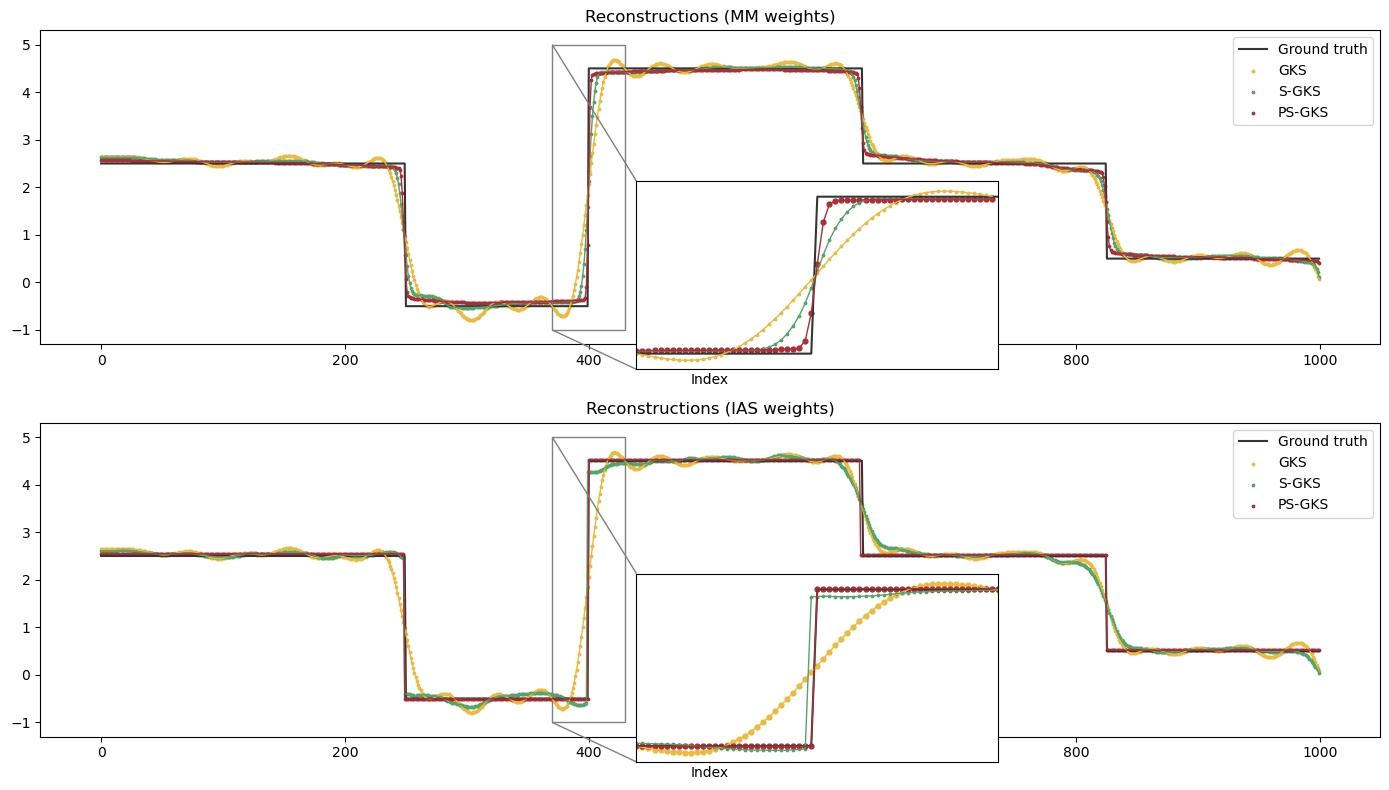

In [34]:
marker_size = 3.0
line_width = 1.0


fig, axs = plt.subplots(2,1,figsize=(14,8))



plot_idx = 0
grid = [i for i in range(len(v_gks_data["x"]))]

# Plot main axs

axs[plot_idx].plot(grid, ground_truth, color="C9", label="Ground truth")

method = "GKS"
axs[plot_idx].plot( grid, v_gks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width )
axs[plot_idx].scatter( grid, v_gks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method  )

method = "S-GKS"
axs[plot_idx].plot( grid, mm_sgks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, mm_sgks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)

method = "PS-GKS"
axs[plot_idx].plot( grid, mm_psgks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, mm_psgks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)


# Do inset axs
inset_ax = inset_axes(axs[plot_idx], width="30%", height="30%", bbox_to_anchor=(0.13, -0.78, 0.9, 2.0), # _, _, width, height
                      bbox_transform=axs[plot_idx].transAxes, loc='center')

start_idx, stop_idx = 400-30, 400+30
zoom_xlim = [start_idx, stop_idx]
zoom_ylim = [-1, 5]
inset_ax.set_xlim(zoom_xlim)
inset_ax.set_ylim(zoom_ylim)
inset_ax.set_xticks([])
inset_ax.set_yticks([])
# inset_ax.set_title('Inset')
rect = patches.Rectangle((zoom_xlim[0], zoom_ylim[0]),
                         zoom_xlim[1] - zoom_xlim[0],  # Width of the rectangle
                         zoom_ylim[1] - zoom_ylim[0],  # Height of the rectangle
                         linewidth=0.5, edgecolor='gray', facecolor='none', linestyle='--')
axs[plot_idx].add_patch(rect)
mark_inset(axs[plot_idx], inset_ax, loc1=2, loc2=3, fc="none", ec="0.5")


inset_ax.plot(grid, ground_truth, color="C9", label="Ground truth")

method = "GKS"
inset_ax.plot( grid[start_idx:stop_idx], v_gks_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], lw=line_width )
inset_ax.scatter( grid[start_idx:stop_idx], v_gks_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method  )

method = "S-GKS"
inset_ax.plot( grid[start_idx:stop_idx], mm_sgks_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid[start_idx:stop_idx], mm_sgks_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)

method = "PS-GKS"
inset_ax.plot( grid[start_idx:stop_idx], mm_psgks_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid[start_idx:stop_idx], mm_psgks_data["x"][start_idx:stop_idx], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=4*marker_size , label=method)


axs[plot_idx].legend()
axs[plot_idx].set_title("Reconstructions (MM weights)")
axs[plot_idx].set_xlabel("Index")




plot_idx = 1

axs[plot_idx].plot(grid, ground_truth, color="C9", label="Ground truth")

method = "GKS"
axs[plot_idx].plot( grid, v_gks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, v_gks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method )

method = "S-GKS"
axs[plot_idx].plot( grid, ias_sgks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, ias_sgks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)


method = "PS-GKS"
axs[plot_idx].plot( grid, ias_psgks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, ias_psgks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)



# Do inset axs
inset_ax = inset_axes(axs[plot_idx], width="30%", height="30%", bbox_to_anchor=(0.13, -0.78, 0.9, 2.0), # _, _, width, height
                      bbox_transform=axs[plot_idx].transAxes, loc='center')

start_idx, stop_idx = 400-30, 400+30
zoom_xlim = [start_idx, stop_idx]
zoom_ylim = [-1, 5]
inset_ax.set_xlim(zoom_xlim)
inset_ax.set_ylim(zoom_ylim)
inset_ax.set_xticks([])
inset_ax.set_yticks([])
# inset_ax.set_title('Inset')
rect = patches.Rectangle((zoom_xlim[0], zoom_ylim[0]),
                         zoom_xlim[1] - zoom_xlim[0],  # Width of the rectangle
                         zoom_ylim[1] - zoom_ylim[0],  # Height of the rectangle
                         linewidth=0.5, edgecolor='gray', facecolor='none', linestyle='--')
axs[plot_idx].add_patch(rect)
mark_inset(axs[plot_idx], inset_ax, loc1=2, loc2=3, fc="none", ec="0.5")

inset_ax.plot(grid, ground_truth, color="C9", label="Ground truth")


method = "GKS"
inset_ax.plot( grid, v_gks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid, v_gks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=4*marker_size , label=method )

method = "S-GKS"
inset_ax.plot( grid, ias_sgks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid, ias_sgks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size , label=method)


method = "PS-GKS"
inset_ax.plot( grid, ias_psgks_data["x"], color=method_colors[method], ls=method_lines[method], lw=line_width)
inset_ax.scatter( grid, ias_psgks_data["x"], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=4*marker_size , label=method)




axs[plot_idx].legend()
axs[plot_idx].set_title("Reconstructions (IAS weights)")
axs[plot_idx].set_xlabel("Index")


fig.tight_layout()
fig.savefig("intro_1d_cosine_reconstructions.png", dpi=250, bbox_inches="tight")
fig.savefig("intro_1d_cosine_reconstructions.eps", format="eps", dpi=250, bbox_inches="tight")

plt.show()

## Basis plots

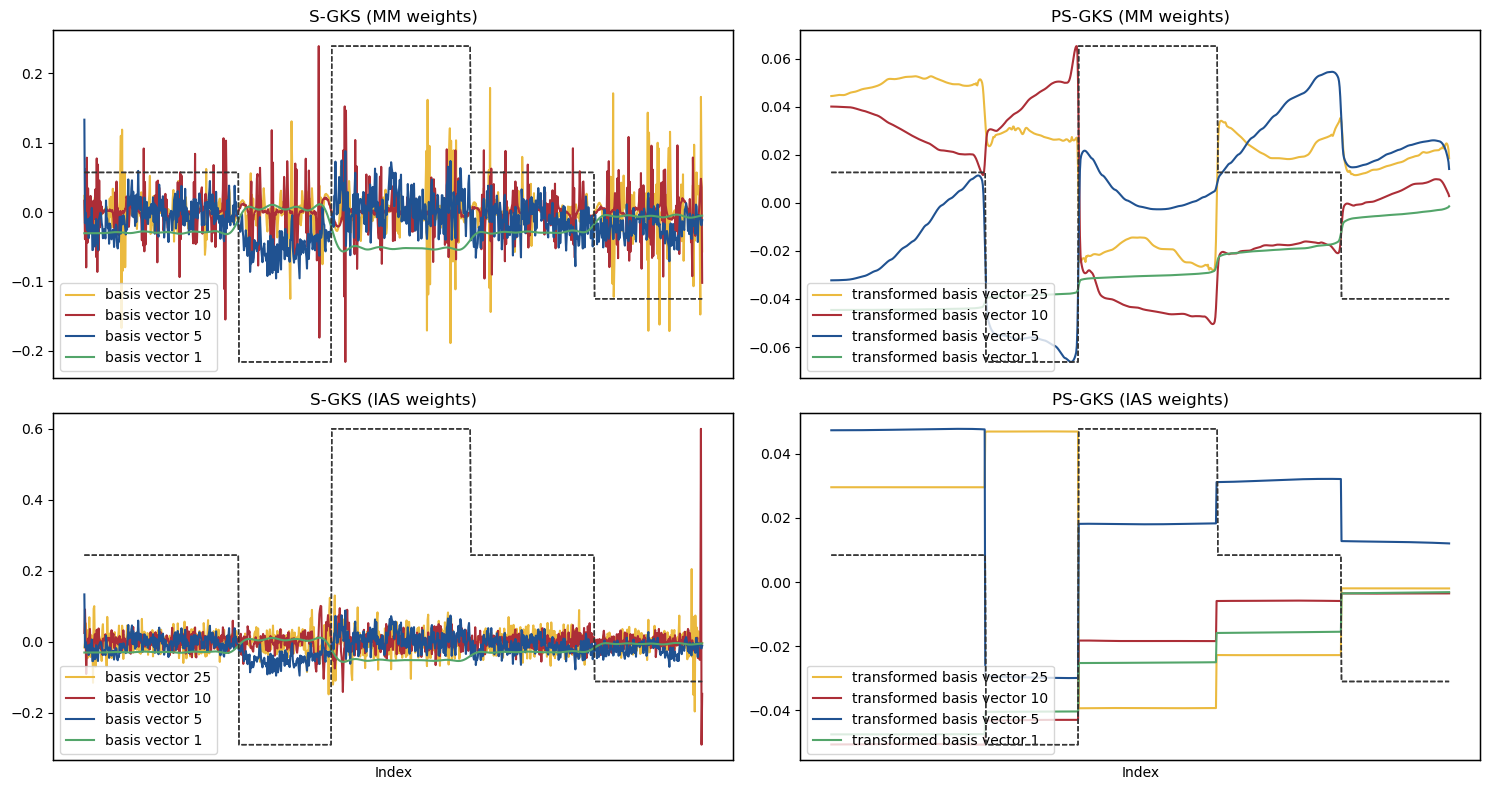

In [35]:
fig, axs = plt.subplots(2,2, figsize=(15,8))

loc = "lower left"
truth_lw = 1

kks = [0, 4, 9, 24]

for j, kk in enumerate(reversed(kks)):

    axs[0,0].plot(mm_sgks_data["V"][:,kk], label=f"basis vector {kk+1}", color=f"C{j+1}")
    axs[0,0].legend(loc=loc)
    axs[0,0].set_xticks([])
    axs[0,0].set_title("S-GKS (MM weights)")
    axst = axs[0,0].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])



for j, kk in enumerate(reversed(kks)):

    axs[0,1].plot(mm_psgks_data["Lopinv"] @ mm_psgks_data["V"][:,kk] / np.linalg.norm(mm_psgks_data["Lopinv"] @ mm_psgks_data["V"][:,kk]), label=f"transformed basis vector {kk+1}", color=f"C{j+1}")
    axs[0,1].legend(loc=loc)
    axs[0,1].set_xticks([])
    axs[0,1].set_title("PS-GKS (MM weights)")
    axst = axs[0,1].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])


# for j, kk in enumerate(reversed(kks)):

#     axs[0,2].plot(mm_fkdata["Z"][:,kk] / np.linalg.norm(mm_fkdata["Z"][:,kk]), label=f" basis vector {kk+1}", color=f"C{j+1}")
#     axs[0,2].legend(loc=loc)
#     axs[0,2].set_xticks([])
#     axs[0,2].set_title("FGK (MM weights)")
#     axst = axs[0,2].twinx()
#     axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
#     #axst.set_yticks([0, 2, 4, 6])
#     axst.set_yticks([])




for j, kk in enumerate(reversed(kks)):

    axs[1,0].plot(ias_sgks_data["V"][:,kk], label=f"basis vector {kk+1}", color=f"C{j+1}")
    axs[1,0].legend(loc=loc)
    axs[1,0].set_xticks([])
    axs[1,0].set_xlabel("Index")
    axs[1,0].set_title("S-GKS (IAS weights)")
    axst = axs[1,0].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])



for j, kk in enumerate(reversed(kks)):

    axs[1,1].plot(ias_psgks_data["Lopinv"] @ ias_psgks_data["V"][:,kk] / np.linalg.norm(ias_psgks_data["Lopinv"] @ ias_psgks_data["V"][:,kk]), label=f"transformed basis vector {kk+1}", color=f"C{j+1}")
    axs[1,1].legend(loc=loc)
    axs[1,1].set_xticks([])
    axs[1,1].set_title("PS-GKS (IAS weights)")
    axs[1,1].set_xlabel("Index")
    axst = axs[1,1].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    axst.set_yticks([])
    #axst.set_yticks([0, 2, 4, 6])



# for j, kk in enumerate(reversed(kks)):

#     axs[1,2].plot(ias_fkdata["Z"][:,kk] / np.linalg.norm(ias_fkdata["Z"][:,kk]), label=f" basis vector {kk+1}", color=f"C{j+1}")
#     axs[1,2].legend(loc=loc)
#     axs[1,2].set_xticks([])
#     axs[1,2].set_title("FGK (IAS weights)")
#     axst = axs[1,2].twinx()
#     axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
#     #axst.set_yticks([0, 2, 4, 6])
#     axst.set_yticks([])


fig.tight_layout()
fig.savefig("intro_1d_cosine_example_basis_vectors_all.png", dpi=250, bbox_inches=None)
fig.savefig("intro_1d_cosine_example_basis_vectors_all.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()

## Performance plot

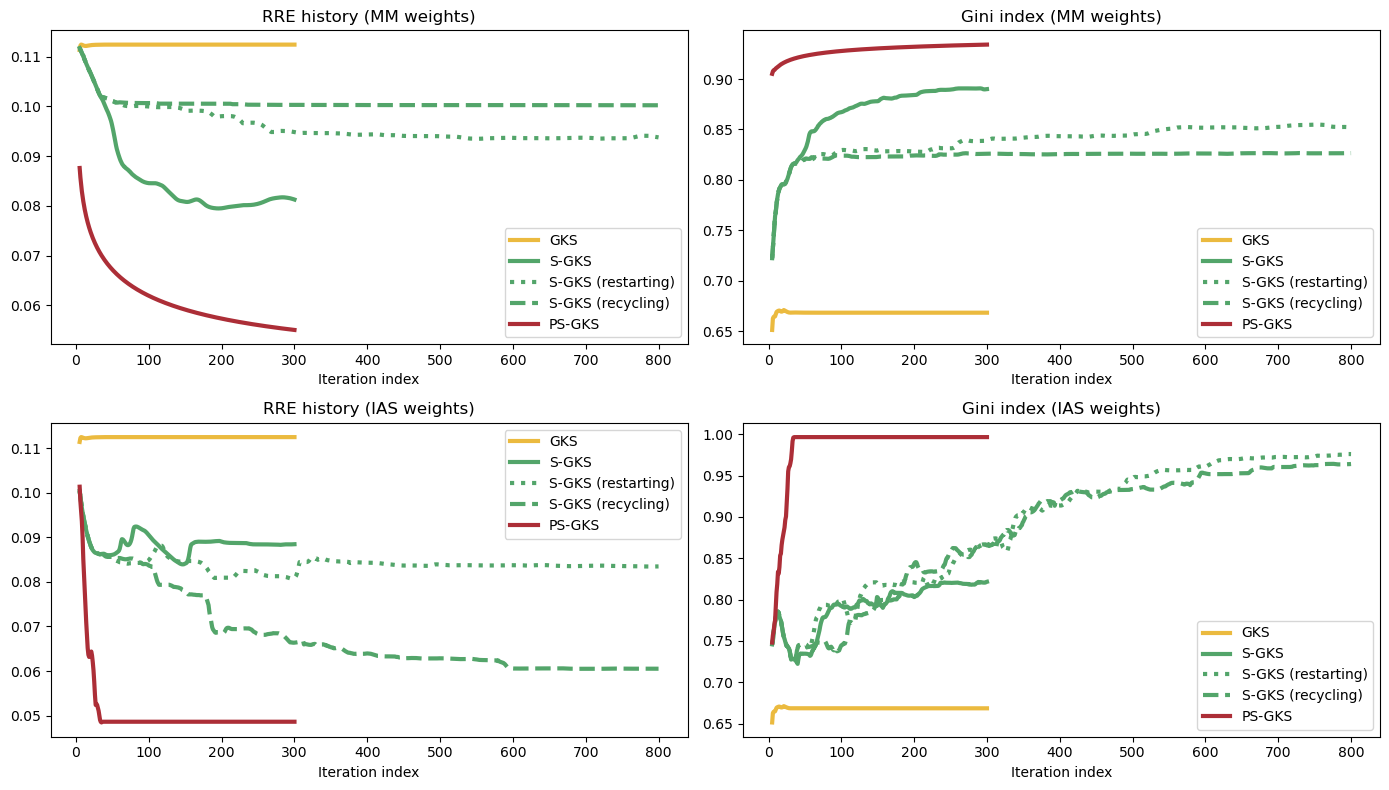

In [36]:
metric = "gini_indices"
#metric = "hoyer_indices"
# metric = "rre_history"
start_idx = 5
marker_size = 5.0
line_width = 3.0

fig, axs = plt.subplots(2,2,figsize=(14,8))


# First plot
plot_idx = (0,0)
plot_title = "RRE history (MM weights)"
metric = "rre_history"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)

method = "resS-GKS"
grid = [i for i in range(start_idx, len(mm_resdata[metric]))]
axs[plot_idx].plot( grid, mm_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label="S-GKS (restarting)")
#axs[plot_idx].scatter( grid, mm_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "recS-GKS"
grid = [i for i in range(start_idx, len(mm_recdata[metric]))]
axs[plot_idx].plot( grid, mm_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label="S-GKS (recycling)")
#axs[plot_idx].scatter( grid, mm_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "PS-GKS"
grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)



# First plot
plot_idx = (1,0)
plot_title = "RRE history (IAS weights)"
metric = "rre_history"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "resS-GKS"
grid = [i for i in range(start_idx, len(ias_resdata[metric]))]
axs[plot_idx].plot( grid, ias_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label="S-GKS (restarting)")
#axs[plot_idx].scatter( grid, ias_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "recS-GKS"
grid = [i for i in range(start_idx, len(ias_recdata[metric]))]
axs[plot_idx].plot( grid, ias_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label="S-GKS (recycling)")
#axs[plot_idx].scatter( grid, ias_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



method = "PS-GKS"
grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)









# # First plot
# plot_idx = (0,1)
# plot_title = "SSIM history (MM weights)"
# metric = "ssim_history"

# method = "GKS"
# grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
# axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

# method = "S-GKS"
# grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
# axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "resS-GKS"
# grid = [i for i in range(start_idx, len(mm_resdata[metric]))]
# axs[plot_idx].plot( grid, mm_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "recS-GKS"
# grid = [i for i in range(start_idx, len(mm_recdata[metric]))]
# axs[plot_idx].plot( grid, mm_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



# method = "PS-GKS"
# grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
# axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# axs[plot_idx].set_xlabel("Iteration index")
# axs[plot_idx].legend()
# axs[plot_idx].set_title(plot_title)




# # First plot
# plot_idx = (1,1)
# plot_title = "SSIM history (IAS weights)"
# metric = "ssim_history"

# method = "GKS"
# grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
# axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

# method = "S-GKS"
# grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
# axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "resS-GKS"
# grid = [i for i in range(start_idx, len(ias_resdata[metric]))]
# axs[plot_idx].plot( grid, ias_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "recS-GKS"
# grid = [i for i in range(start_idx, len(ias_recdata[metric]))]
# axs[plot_idx].plot( grid, ias_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



# method = "PS-GKS"
# grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
# axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
# axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)




# axs[plot_idx].set_xlabel("Iteration index")
# axs[plot_idx].legend()
# axs[plot_idx].set_title(plot_title)








# First plot
plot_idx = (0,1)
plot_title = "Gini index (MM weights)"
metric = "gini_indices"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



method = "resS-GKS"
grid = [i for i in range(start_idx, len(mm_resdata[metric]))]
axs[plot_idx].plot( grid, mm_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label="S-GKS (restarting)")
#axs[plot_idx].scatter( grid, mm_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "recS-GKS"
grid = [i for i in range(start_idx, len(mm_recdata[metric]))]
axs[plot_idx].plot( grid, mm_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label="S-GKS (recycling)")
#axs[plot_idx].scatter( grid, mm_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)




method = "PS-GKS"
grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)






# First plot
plot_idx = (1,1)
plot_title = "Gini index (IAS weights)"
metric = "gini_indices"

method = "GKS"
grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

method = "S-GKS"
grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "resS-GKS"
grid = [i for i in range(start_idx, len(ias_resdata[metric]))]
axs[plot_idx].plot( grid, ias_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label="S-GKS (restarting)")
#axs[plot_idx].scatter( grid, ias_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "recS-GKS"
grid = [i for i in range(start_idx, len(ias_recdata[metric]))]
axs[plot_idx].plot( grid, ias_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label="S-GKS (recycling)")
#axs[plot_idx].scatter( grid, ias_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


method = "PS-GKS"
grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
#axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


axs[plot_idx].set_xlabel("Iteration index")
axs[plot_idx].legend()
axs[plot_idx].set_title(plot_title)











# # First plot
# plot_idx = (1,2)
# plot_title = "Condition number of projected problem (IAS weights)"
# metric = "cond_ests"

# method = "GKS"
# grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
# axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

# method = "S-GKS"
# grid = [i for i in range(start_idx, len(ias_sgks_data[metric]))]
# axs[plot_idx].plot( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "resS-GKS"
# grid = [i for i in range(start_idx, len(ias_resdata[metric]))]
# axs[plot_idx].plot( grid, ias_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label="S-GKS (restarting)")
# #axs[plot_idx].scatter( grid, ias_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "recS-GKS"
# grid = [i for i in range(start_idx, len(ias_recdata[metric]))]
# axs[plot_idx].plot( grid, ias_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label="S-GKS (recycling)")
# #axs[plot_idx].scatter( grid, ias_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "PS-GKS"
# grid = [i for i in range(start_idx, len(ias_psgks_data[metric]))]
# axs[plot_idx].plot( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, ias_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# axs[plot_idx].set_xlabel("Iteration index")
# axs[plot_idx].legend()
# axs[plot_idx].set_title(plot_title)
# axs[plot_idx].set_yscale("log")







# # First plot
# plot_idx = (0,2)
# plot_title = "Condition number of projected problem (MM weights)"
# metric = "cond_ests"

# method = "GKS"
# grid = [i for i in range(start_idx, len(v_gks_data[metric]))]
# axs[plot_idx].plot( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, v_gks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method )

# method = "S-GKS"
# grid = [i for i in range(start_idx, len(mm_sgks_data[metric]))]
# axs[plot_idx].plot( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_sgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)



# method = "resS-GKS"
# grid = [i for i in range(start_idx, len(mm_resdata[metric]))]
# axs[plot_idx].plot( grid, mm_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label="S-GKS (restarting)")
# #axs[plot_idx].scatter( grid, mm_resdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# method = "recS-GKS"
# grid = [i for i in range(start_idx, len(mm_recdata[metric]))]
# axs[plot_idx].plot( grid, mm_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label="S-GKS (recycling)")
# #axs[plot_idx].scatter( grid, mm_recdata[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)




# method = "PS-GKS"
# grid = [i for i in range(start_idx, len(mm_psgks_data[metric]))]
# axs[plot_idx].plot( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width, label=method)
# #axs[plot_idx].scatter( grid, mm_psgks_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=marker_size, label=method)


# axs[plot_idx].set_xlabel("Iteration index")
# axs[plot_idx].legend()
# axs[plot_idx].set_title(plot_title)
# axs[plot_idx].set_yscale("log")





fig.tight_layout()
fig.savefig("intro_1d_cosine_performance", dpi=250, bbox_inches=None)
fig.savefig("intro_1d_cosine_performance.eps", format="eps", dpi=250, bbox_inches=None)



plt.show()